# Validação cruzada temporal no horizonte de planejamento: Minerva

Este notebook complementa o 2.0. O 2.0 escolheu a curva de demanda prevendo um dia por vez, sempre
com todas as vendas anteriores conhecidas. Aqui o modelo é avaliado da forma como será usado pelo
otimizador: ele é ajustado em uma segunda-feira e precisa prever as duas semanas seguintes sem
conhecer nenhuma venda desse período.

Os mesmos candidatos do 2.0 são reavaliados com esse protocolo, nas mesmas três rodadas:
calendário, forma funcional e tendência. Ao final, um desafio opcional verifica se acrescentar
memória de volume (lag ou nível recente) compensaria a complexidade adicional que ela traria ao
otimizador. Nenhuma informação do conjunto de teste é utilizada.

## 1. Terminologia

Os nomes abaixo são usados de forma consistente em todo o notebook:

| Termo | Dados | Função |
|---|---|---|
| **Desenvolvimento** | 01/08/2025 a 31/10/2025 (76 dias) | Tudo que pode ser usado para ajustar e escolher modelos |
| **Ajuste** | Parte do desenvolvimento anterior a cada origem | Estimar coeficientes e smearing |
| **Validação** | Duas semanas do desenvolvimento depois de cada origem | Medir o erro de previsão e escolher o modelo |
| **Teste** | 03/11/2025 a 14/11/2025, fornecido pela Minerva | Avaliação final única do modelo congelado |

O conjunto chamado de *holdout* no 2.0 é o **teste**. Ele não é validação: validação é a parte usada
para escolher o modelo, enquanto o teste só pode ser consultado depois da escolha, para reportar o
erro final. Usar o teste para comparar candidatos o transformaria em validação e deixaria o projeto
sem nenhuma avaliação independente. Por isso, este notebook não carrega o arquivo de teste.

## 2. Contrato da validação

**Pergunta:** qual especificação prevê melhor as duas semanas de um planejamento, quando o modelo
é ajustado antes do início do horizonte e mantido fixo durante todo o período?

**Protocolo de origens semanais:**

1. Cada origem é uma segunda-feira do desenvolvimento.
2. O ajuste usa somente os dias anteriores à origem. A primeira origem é a primeira segunda-feira com
   pelo menos 30 observações de ajuste, cerca de seis semanas de histórico.
3. A validação contém os dias dos 14 dias seguintes à origem, ou seja, duas semanas comerciais. Só
   entram origens cujas duas semanas, de segunda a sexta, estejam inteiramente no desenvolvimento.
4. O modelo é ajustado uma vez por origem e não é atualizado dentro do horizonte.

Para modelos sem memória de volume, preço e calendário são conhecidos antes da decisão. A única
diferença em relação ao 2.0 é que o modelo deixa de ser reajustado a cada dia e passa a ser avaliado
em vários períodos, em vez de apenas em 09/10 a 31/10.

As origens se sobrepõem: a segunda semana de uma origem é a primeira semana da origem seguinte.
Isso aumenta o número de comparações, mas as rodadas não são independentes. Por esse motivo, a
decisão usa comparação pareada e uma regra conservadora.

**Métricas.** A restrição do otimizador é a meta **semanal** de volume. Por isso, a métrica primária
é o **WMAPE semanal**: soma dos erros absolutos semanais dividida pelo volume semanal realizado. As
demais métricas da seção 6 são complementares.

**Regra de decisão:** o campeão do 2.0, `P3`, só é substituído por um desafiante que cumpra todas
as condições abaixo:

- vencer `P3` no WMAPE semanal em **todas** as origens, que é o único resultado com p-valor
  unilateral do teste do sinal abaixo de 5% com seis rodadas;
- não piorar o WMAPE diário médio em mais de 1 ponto percentual;
- apresentar inclinação de preço negativa e previsões positivas em todas as origens;
- nos modelos com lag, manter o mesmo sinal do coeficiente do lag em todas as origens.

A mesma regra é aplicada em todas as rodadas. Ela é deliberadamente rígida: com seis origens
sobrepostas, diferenças de poucos pontos podem surgir por acaso, e o modelo atual já foi avaliado
como adequado pela Minerva.

In [1]:
from pathlib import Path
import os

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from scipy import stats

DATA_PATH = ROOT / 'data/processed/minerva_modelagem_treino.csv'
RESTRICOES_PATH = ROOT / 'data/interim/minerva_restricoes.csv'
RANKINGS_20 = {
    'calendário': ROOT / 'reports/tables/02_ranking_calendario.csv',
    'forma': ROOT / 'reports/tables/02_ranking_forma.csv',
    'tendência': ROOT / 'reports/tables/02_ranking_tendencia.csv',
}
FIGURES_DIR = ROOT / 'reports/figures'
TABLES_DIR = ROOT / 'reports/tables'
for directory in [FIGURES_DIR, TABLES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

ORDEM_DIAS = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']
DIAS_UTEIS = ORDEM_DIAS[:5]
MINIMO_AJUSTE = 30
HORIZONTE_DIAS = 14
REFERENCIA = 'P3'
TOLERANCIA_TEXTO = 0.05
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 40)

## 3. Carregamento do desenvolvimento e das tolerâncias

São carregados apenas a base processada de desenvolvimento e o arquivo de restrições da instância. O
segundo contém a meta semanal, a tolerância e a variação máxima de preço; ele é usado somente para
avaliar se o erro semanal do modelo cabe dentro da faixa de tolerância. O enunciado também menciona
uma tolerância de 5%, que é avaliada como referência mais exigente.

As colunas de memória usadas no desafio opcional da seção 11 são criadas aqui, uma única vez:

- `lag_linha`: `ln(volume)` da linha anterior da base, definição usada na tabela do colega;
- `lag_util`: `ln(volume)` do dia útil anterior. Na segunda-feira, é a sexta, mesmo que existam
  vendas no fim de semana.

In [2]:
dados = pd.read_csv(DATA_PATH, parse_dates=['data', 'inicio_semana'])
dados = dados.sort_values('data').reset_index(drop=True)
if dados['data'].duplicated().any():
    raise ValueError('Há datas duplicadas no desenvolvimento.')
if (dados[['volume_kg', 'preco_kg']] <= 0).any().any():
    raise ValueError('Volume e preço devem ser positivos.')

dados['ln_volume'] = np.log(dados['volume_kg'])
dados['ln_preco'] = np.log(dados['preco_kg'])
dados['lag_linha'] = dados['ln_volume'].shift()
dados['lag_util'] = (
    dados['ln_volume'].where(dados['dia_semana'].isin(DIAS_UTEIS)).ffill().shift()
)

restricoes = pd.read_csv(RESTRICOES_PATH)
TOLERANCIA_INSTANCIA = float(restricoes['Tolerância %'].iloc[0])
TOLERANCIAS = sorted({TOLERANCIA_TEXTO, TOLERANCIA_INSTANCIA})

segundas = dados.loc[dados['dia_semana'] == 'Segunda'].copy()
segundas['dia anterior na base'] = dados['dia_semana'].shift().loc[segundas.index]
auditoria = pd.DataFrame({
    'Indicador': [
        'Observações', 'Data inicial', 'Data final', 'Observações de fim de semana',
        'Segundas precedidas de sábado ou domingo na base',
        'Tolerância da instância', 'Tolerância do enunciado',
    ],
    'Resultado': [
        len(dados), dados['data'].min().date(), dados['data'].max().date(),
        int((~dados['dia_semana'].isin(DIAS_UTEIS)).sum()),
        f"{int(segundas['dia anterior na base'].isin(['Sábado', 'Domingo']).sum())} de {len(segundas)}",
        f'{TOLERANCIA_INSTANCIA:.0%}', f'{TOLERANCIA_TEXTO:.0%}',
    ],
})
display(auditoria)

,Indicador,Resultado
0,Observações,76
1,Data inicial,2025-08-01
2,Data final,2025-10-31
3,Observações de fim de semana,10
4,Segundas precedidas de sábado ou domingo na base,8 de 13
5,Tolerância da instância,30%
6,Tolerância do enunciado,5%


**Resultado do carregamento.** A base de desenvolvimento contém 76 observações entre 01/08/2025 e 31/10/2025, das quais apenas 10 são de fim de semana. Em 8 das 13 segundas-feiras, a linha anterior da base é um sábado ou domingo; esse dado será retomado no desafio de memória. A tolerância da instância é 30%; a do enunciado, 5%. O arquivo de teste não foi carregado.

## 4. Origens da validação

A célula abaixo constrói as origens a partir das regras do contrato e verifica que cada janela de
ajuste contém todos os contextos de calendário. Sem pelo menos um fim de semana no ajuste, o
coeficiente desse contexto não poderia ser estimado.

In [3]:
ultima_data = dados['data'].max()
origens = []
for origem in dados.loc[dados['dia_semana'] == 'Segunda', 'data']:
    ajuste = dados.loc[dados['data'] < origem]
    ultima_sexta = origem + pd.Timedelta(days=11)
    if len(ajuste) >= MINIMO_AJUSTE and ultima_sexta <= ultima_data:
        if set(ajuste['dia_semana']) != set(ORDEM_DIAS):
            raise ValueError(f'Ajuste sem todos os dias da semana na origem {origem.date()}.')
        origens.append(origem)

linhas_origens = []
for numero, origem in enumerate(origens, start=1):
    ajuste = dados.loc[dados['data'] < origem]
    validacao = dados.loc[
        (dados['data'] >= origem)
        & (dados['data'] < origem + pd.Timedelta(days=HORIZONTE_DIAS))
    ]
    linhas_origens.append({
        'Rodada': numero,
        'Origem': origem.date(),
        'Ajuste até': ajuste['data'].max().date(),
        'Observações de ajuste': len(ajuste),
        'Validação até': validacao['data'].max().date(),
        'Observações de validação': len(validacao),
        'Volume validado (kg)': round(float(validacao['volume_kg'].sum()), 2),
    })
tabela_origens = pd.DataFrame(linhas_origens).set_index('Rodada')
display(tabela_origens)

,Origem,Ajuste até,Observações de ajuste,Validação até,Observações de validação,Volume validado (kg)
Rodada,,,,,,
1,2025-09-15,2025-09-12,34,2025-09-28,12,161.88
2,2025-09-22,2025-09-19,39,2025-10-05,13,148.71
3,2025-09-29,2025-09-28,46,2025-10-11,12,312.99
4,2025-10-06,2025-10-05,52,2025-10-19,13,530.35
5,2025-10-13,2025-10-11,58,2025-10-26,13,375.35
6,2025-10-20,2025-10-19,65,2025-10-31,11,144.04


**Resultado das origens.** As regras produziram seis origens, de 15/09 a 20/10. O ajuste cresce de 34 para 65 observações, e cada validação contém de 11 a 13 dias, com volume entre `144` e `530 kg`. A grande variação desse volume já antecipa que algumas rodadas serão bem mais difíceis que outras: as rodadas 3 a 5 incluem as semanas de pico de 06/10 e 13/10. Todas as janelas de ajuste continham os sete dias da semana, condição necessária para estimar `P2`.

## 5. Candidatos e funções de validação

Os candidatos sem memória são os mesmos do 2.0:

| Código | Forma | Calendário | Tendência |
|---|---|---|---|
| `P0` | potência | nenhum | não |
| `P1` | potência | dia útil × fim de semana | não |
| `P2` | potência | sete dias da semana | não |
| `P3` | potência | segunda–quinta × sexta × fim de semana | não |
| `P4` | potência | segunda × terça–quinta × sexta × fim de semana | não |
| `E1` | exponencial | igual a `P3` | não |
| `L1` | linear | igual a `P3` | não |
| `T1` | potência | igual a `P3` | sim |

A forma de potência é `ln(volume) ~ ln(preço) + calendário`; a exponencial, `ln(volume) ~ preço +
calendário`; a linear, `volume ~ preço + calendário`. As formas logarítmicas recebem smearing
calculado em cada janela de ajuste.

Os candidatos com memória, avaliados apenas no desafio opcional da seção 11, acrescentam a `P3` ou
`P4`:

| Sufixo | Memória |
|---|---|
| `-LL` | `ln(volume)` da linha anterior da base |
| `-LU` | `ln(volume)` do dia útil anterior |
| `-N` | nível recente: média dos resíduos da última semana do ajuste somada a todo o horizonte |

Nos modelos com lag, o volume anterior de cada dia do horizonte é a **previsão** do dia anterior, pois
o otimizador não conhece vendas futuras. A recursão ocorre em `ln(volume)`, e o smearing é aplicado
somente na conversão final para kg, para não acumular a correção a cada passo.

In [4]:
MAPAS_CONTEXTO = {
    'none': {dia: 'Geral' for dia in ORDEM_DIAS},
    'weekend': {
        dia: ('Fim_de_semana' if dia in ['Sábado', 'Domingo'] else 'Dia_util')
        for dia in ORDEM_DIAS
    },
    'weekday': {dia: dia for dia in ORDEM_DIAS},
    'grouped': {
        dia: (
            'Segunda_a_Quinta' if dia in ORDEM_DIAS[:4]
            else 'Sexta' if dia == 'Sexta'
            else 'Fim_de_semana'
        )
        for dia in ORDEM_DIAS
    },
    'grouped4': {
        dia: (
            'Segunda' if dia == 'Segunda'
            else 'Terca_a_Quinta' if dia in ORDEM_DIAS[1:4]
            else 'Sexta' if dia == 'Sexta'
            else 'Fim_de_semana'
        )
        for dia in ORDEM_DIAS
    },
}
ORDEM_CONTEXTO = {
    'none': ['Geral'],
    'weekend': ['Dia_util', 'Fim_de_semana'],
    'weekday': ORDEM_DIAS,
    'grouped': ['Segunda_a_Quinta', 'Sexta', 'Fim_de_semana'],
    'grouped4': ['Terca_a_Quinta', 'Segunda', 'Sexta', 'Fim_de_semana'],
}
COLUNAS_LAG = {'lag_linha', 'lag_util'}
FAMILIAS_LOG = {'power', 'exponential'}


def especificacao(family='power', calendar='grouped', trend=False, memory=None):
    return {'family': family, 'calendar': calendar, 'trend': trend, 'memory': memory}


CANDIDATOS_SEM_MEMORIA = {
    'P0': especificacao(calendar='none'),
    'P1': especificacao(calendar='weekend'),
    'P2': especificacao(calendar='weekday'),
    'P3': especificacao(),
    'P4': especificacao(calendar='grouped4'),
    'E1': especificacao(family='exponential'),
    'L1': especificacao(family='linear'),
    'T1': especificacao(trend=True),
}
CANDIDATOS_MEMORIA = {
    'P3-LL': especificacao(memory='lag_linha'),
    'P4-LL': especificacao(calendar='grouped4', memory='lag_linha'),
    'P3-LU': especificacao(memory='lag_util'),
    'P4-LU': especificacao(calendar='grouped4', memory='lag_util'),
    'P3-N': especificacao(memory='nivel'),
    'P4-N': especificacao(calendar='grouped4', memory='nivel'),
}
CANDIDATOS = {**CANDIDATOS_SEM_MEMORIA, **CANDIDATOS_MEMORIA}
RODADAS = {
    'calendário': ['P0', 'P1', 'P2', 'P3', 'P4'],
    'forma': ['P3', 'E1', 'L1'],
    'tendência': ['P3', 'T1'],
    'memória': ['P3', 'P4', *CANDIDATOS_MEMORIA],
}


def matriz_desenho(base, specification):
    if specification['family'] == 'power':
        preco = base['ln_preco'].astype(float).rename('ln_preco')
    else:
        preco = (base['preco_kg'].astype(float) / 100).rename('preco_100')
    matriz = pd.DataFrame({'const': 1.0, preco.name: preco}, index=base.index)
    calendar = specification['calendar']
    contexto = base['dia_semana'].map(MAPAS_CONTEXTO[calendar])
    for nome in ORDEM_CONTEXTO[calendar][1:]:
        matriz[f'contexto_{nome}'] = (contexto == nome).astype(float)
    if specification['trend']:
        matriz['indice_tempo_10'] = base['indice_tempo'].astype(float) / 10
    if specification['memory'] in COLUNAS_LAG:
        matriz['lag_ln_volume'] = base[specification['memory']].astype(float)
    return matriz


def ajustar_candidato(ajuste, specification):
    memory = specification['memory']
    base = ajuste.dropna(subset=[memory]) if memory in COLUNAS_LAG else ajuste
    log = specification['family'] in FAMILIAS_LOG
    resposta = base['ln_volume'] if log else base['volume_kg']
    modelo = sm.OLS(resposta, matriz_desenho(base, specification)).fit()
    smearing = float(np.exp(modelo.resid).mean()) if log else 1.0
    deslocamento = 0.0
    if memory == 'nivel':
        recente = base['data'] >= base['data'].max() - pd.Timedelta(days=6)
        deslocamento = float(modelo.resid[recente].mean())
    return modelo, smearing, deslocamento


def prever_horizonte(modelo, smearing, deslocamento, ajuste, horizonte, specification):
    memory = specification['memory']
    if memory not in COLUNAS_LAG:
        linear = np.asarray(
            modelo.predict(matriz_desenho(horizonte, specification)), dtype=float
        ) + deslocamento
        if specification['family'] in FAMILIAS_LOG:
            return np.exp(linear) * smearing
        return linear
    ultimo_linha = float(ajuste['ln_volume'].iloc[-1])
    ultimo_util = float(
        ajuste.loc[ajuste['dia_semana'].isin(DIAS_UTEIS), 'ln_volume'].iloc[-1]
    )
    ln_previstos = []
    for indice in horizonte.index:
        linha = horizonte.loc[[indice]].copy()
        linha[memory] = ultimo_linha if memory == 'lag_linha' else ultimo_util
        ln_previsto = float(
            np.asarray(modelo.predict(matriz_desenho(linha, specification)))[0]
        )
        ln_previstos.append(ln_previsto)
        ultimo_linha = ln_previsto
        if linha['dia_semana'].iloc[0] in DIAS_UTEIS:
            ultimo_util = ln_previsto
    return np.exp(np.asarray(ln_previstos)) * smearing


def elasticidade_longo_prazo(modelo, specification, ajuste):
    inclinacao = float(modelo.params.iloc[1])
    rho = float(modelo.params.get('lag_ln_volume', 0.0))
    if specification['family'] == 'power':
        return inclinacao / (1 - rho)
    if specification['family'] == 'exponential':
        return inclinacao * float(ajuste['preco_kg'].median()) / 100
    return np.nan


def validacao_origens(base, code, specification, origens):
    previsoes, coeficientes = [], []
    for numero, origem in enumerate(origens, start=1):
        ajuste = base.loc[base['data'] < origem]
        horizonte = base.loc[
            (base['data'] >= origem)
            & (base['data'] < origem + pd.Timedelta(days=HORIZONTE_DIAS))
        ]
        modelo, smearing, deslocamento = ajustar_candidato(ajuste, specification)
        previsto = prever_horizonte(
            modelo, smearing, deslocamento, ajuste, horizonte, specification
        )
        previsoes.append(pd.DataFrame({
            'candidato': code,
            'rodada': numero,
            'origem': origem,
            'data': horizonte['data'].to_numpy(),
            'inicio_semana': horizonte['inicio_semana'].to_numpy(),
            'dia_semana': horizonte['dia_semana'].to_numpy(),
            'preco_kg': horizonte['preco_kg'].to_numpy(),
            'volume_real_kg': horizonte['volume_kg'].to_numpy(),
            'volume_previsto_kg': previsto,
        }))
        coeficientes.append({
            'candidato': code,
            'rodada': numero,
            'origem': origem.date(),
            'Linhas de ajuste': int(modelo.nobs),
            'Inclinação de preço': float(modelo.params.iloc[1]),
            'Coeficiente do lag (ρ)': float(modelo.params.get('lag_ln_volume', 0.0)),
            'Elasticidade longo prazo': elasticidade_longo_prazo(
                modelo, specification, ajuste
            ),
            'Smearing': smearing,
            'Deslocamento de nível': deslocamento,
        })
    return pd.concat(previsoes, ignore_index=True), pd.DataFrame(coeficientes)


def painel_erros(previsoes):
    real = previsoes['volume_real_kg']
    previsto = previsoes['volume_previsto_kg']
    erro = previsto - real
    semanal = previsoes.groupby('inicio_semana')[
        ['volume_real_kg', 'volume_previsto_kg']
    ].sum()
    erro_semanal = semanal['volume_previsto_kg'] - semanal['volume_real_kg']
    erro_semanal_relativo = erro_semanal / semanal['volume_real_kg']
    painel = {
        'WMAPE': float(erro.abs().sum() / real.sum()),
        'MAE': float(erro.abs().mean()),
        'RMSE': float(np.sqrt(np.mean(erro**2))),
        'Erro absoluto mediano': float(erro.abs().median()),
        'sMAPE': float((2 * erro.abs() / (real.abs() + previsto.abs())).mean()),
        'RMSLE': (
            float(np.sqrt(np.mean((np.log1p(previsto) - np.log1p(real)) ** 2)))
            if (previsto > -1).all()
            else np.nan
        ),
        'MAPE (diagnóstico)': float((erro.abs() / real).mean()),
        'Viés (%)': float(erro.sum() / real.sum()),
        'WMAPE semanal': float(
            erro_semanal.abs().sum() / semanal['volume_real_kg'].sum()
        ),
        'Pior erro semanal (%)': float(erro_semanal_relativo.abs().max()),
    }
    for tolerancia in TOLERANCIAS:
        painel[f'Semanas dentro de ±{tolerancia:.0%}'] = float(
            (erro_semanal_relativo.abs() <= tolerancia).mean()
        )
    painel['Previsão mínima'] = float(previsto.min())
    return painel


def contar_parametros(specification):
    return matriz_desenho(dados, specification).shape[1] + (
        1 if specification['memory'] == 'nivel' else 0
    )


catalogo = pd.DataFrame([
    {
        'Código': code,
        'Forma': spec['family'],
        'Calendário': spec['calendar'],
        'Tendência': spec['trend'],
        'Memória': spec['memory'] or 'nenhuma',
        'Parâmetros': contar_parametros(spec),
    }
    for code, spec in CANDIDATOS.items()
]).set_index('Código')
display(catalogo)

,Forma,Calendário,Tendência,Memória,Parâmetros
Código,,,,,
P0,power,none,False,nenhuma,2
P1,power,weekend,False,nenhuma,3
P2,power,weekday,False,nenhuma,8
P3,power,grouped,False,nenhuma,4
P4,power,grouped4,False,nenhuma,5
E1,exponential,grouped,False,nenhuma,4
L1,linear,grouped,False,nenhuma,4
T1,power,grouped,True,nenhuma,5
P3-LL,power,grouped,False,lag_linha,5


**Resultado da definição.** São oito candidatos sem memória, idênticos aos do 2.0, e seis candidatos com memória. O número de parâmetros vai de dois, em `P0`, a oito, em `P2`. Nas variantes `N`, o deslocamento de nível é contado como parâmetro adicional, pois também é estimado com o histórico de ajuste.

## 6. Execução da validação

Todos os candidatos, com e sem memória, são ajustados nas mesmas origens e avaliados nos mesmos
dias. As seções seguintes apenas recortam esse resultado comum por rodada. As métricas têm papéis
diferentes:

| Métrica | O que mede | Papel |
|---|---|---|
| **WMAPE semanal** | Erro do volume total de cada semana, a grandeza da meta | **Primária** |
| WMAPE | Erro diário ponderado pelo volume | Secundária |
| Viés (%) | Se o modelo erra sistematicamente para cima (+) ou para baixo (−) | Secundária: viés desloca o volume semanal |
| Pior erro semanal (%) | A semana mais mal prevista da rodada | Risco |
| Semanas dentro de ±tolerância | Proporção de semanas com erro dentro da tolerância da meta | Leitura direta para o otimizador |
| MAE, RMSE, erro mediano | Erro diário em kg; o RMSE penaliza erros grandes | Complementares |
| sMAPE, RMSLE | Erro relativo e erro na escala logarítmica | Diagnóstico |
| MAPE | Erro percentual simples | Só diagnóstico: explode em dias de volume próximo de zero |

A tabela abaixo mostra o WMAPE semanal de cada candidato sem memória em cada origem.

In [5]:
previsoes_por_candidato = {}
coeficientes_por_candidato = []
linhas_metricas = []
for code, specification in CANDIDATOS.items():
    previsoes, coeficientes = validacao_origens(dados, code, specification, origens)
    previsoes_por_candidato[code] = previsoes
    coeficientes_por_candidato.append(coeficientes)
    for rodada, recorte in previsoes.groupby('rodada'):
        linhas_metricas.append({
            'Código': code,
            'Rodada': rodada,
            'Origem': recorte['origem'].iloc[0].date(),
            **painel_erros(recorte),
        })

metricas_rodada = pd.DataFrame(linhas_metricas)
coeficientes_rodada = pd.concat(coeficientes_por_candidato, ignore_index=True)
previsoes_todas = pd.concat(previsoes_por_candidato.values(), ignore_index=True)
metricas_rodada.to_csv(TABLES_DIR / '021_metricas_por_rodada.csv', index=False)
coeficientes_rodada.to_csv(TABLES_DIR / '021_coeficientes_por_rodada.csv', index=False)
previsoes_todas.to_csv(TABLES_DIR / '021_previsoes_validacao_origens.csv', index=False)

wmape_semanal_rodada = metricas_rodada.pivot(
    index='Origem', columns='Código', values='WMAPE semanal'
)[list(CANDIDATOS)]
print('WMAPE semanal (%) por origem — candidatos sem memória')
display((100 * wmape_semanal_rodada[list(CANDIDATOS_SEM_MEMORIA)]).round(2))

WMAPE semanal (%) por origem — candidatos sem memória


Código,P0,P1,P2,P3,P4,E1,L1,T1
Origem,,,,,,,,
2025-09-15,34.68,28.96,29.13,25.63,26.07,25.60,27.93,56.20
2025-09-22,72.64,46.74,44.88,46.93,46.42,46.86,49.78,94.74
2025-09-29,36.59,41.54,35.78,35.94,35.80,36.29,39.57,33.03
2025-10-06,49.44,54.18,40.03,41.90,40.38,42.31,46.43,53.28
2025-10-13,46.85,44.81,38.27,37.53,37.37,37.52,35.19,37.64
2025-10-20,25.87,18.29,21.58,20.20,22.68,19.00,57.50,28.74


**Resultado da execução.** O WMAPE semanal de `P3` varia de `20,2%` (origem 20/10) a `46,9%` (origem 22/09). Os candidatos com calendário (`P2`, `P3`, `P4`, `E1`) sobem e descem juntos e raramente se afastam mais de 3 pontos entre si em uma mesma origem: a dificuldade é do período, não do modelo. Já `P0`, `L1` e `T1` apresentam rodadas isoladas muito piores, como `72,6%` para `P0` em 22/09, `57,5%` para `L1` em 20/10 e `94,7%` para `T1` em 22/09.

### 6.1 Funções de comparação

Cada rodada é lida em duas tabelas:

- **painel:** média e desvio-padrão (DP) das métricas entre as origens. O DP mostra quanto o erro
  varia de um período para outro. Quando a diferença entre dois modelos é menor que essa oscilação,
  as médias sozinhas não permitem afirmar qual é melhor;
- **comparação pareada:** em quantas origens o desafiante errou menos que `P3` nos mesmos dias. A
  comparação pareada elimina a parte do erro que se deve à dificuldade de cada período. O p-valor do
  teste do sinal responde: se os dois modelos fossem equivalentes, qual seria a chance de o
  desafiante vencer tantas vezes só por acaso?

Diferenças negativas significam erro menor que `P3`.

In [6]:
def montar_painel(codigos):
    recorte = metricas_rodada.loc[metricas_rodada['Código'].isin(codigos)]
    media = recorte.groupby('Código').mean(numeric_only=True)
    desvio = recorte.groupby('Código').std(numeric_only=True)
    coef = coeficientes_rodada.groupby('candidato')
    painel = pd.DataFrame(index=codigos)
    painel['Parâmetros'] = catalogo.loc[codigos, 'Parâmetros']
    painel['WMAPE semanal (%)'] = 100 * media['WMAPE semanal']
    painel['DP WMAPE semanal (p.p.)'] = 100 * desvio['WMAPE semanal']
    painel['WMAPE diário (%)'] = 100 * media['WMAPE']
    painel['DP WMAPE diário (p.p.)'] = 100 * desvio['WMAPE']
    painel['RMSE (kg)'] = media['RMSE']
    painel['DP RMSE (kg)'] = desvio['RMSE']
    painel['MAE (kg)'] = media['MAE']
    painel['Erro absoluto mediano (kg)'] = media['Erro absoluto mediano']
    painel['sMAPE (%)'] = 100 * media['sMAPE']
    painel['RMSLE'] = media['RMSLE']
    painel['Viés (%)'] = 100 * media['Viés (%)']
    painel['Pior erro semanal (%)'] = 100 * media['Pior erro semanal (%)']
    for tolerancia in TOLERANCIAS:
        nome = f'Semanas dentro de ±{tolerancia:.0%}'
        painel[f'{nome} (%)'] = 100 * media[nome]
    painel['Previsão mínima (kg)'] = recorte.groupby('Código')['Previsão mínima'].min()
    painel['Elasticidade longo prazo (mediana)'] = coef['Elasticidade longo prazo'].median()
    painel.index.name = 'Código'
    return painel.sort_values('WMAPE semanal (%)')


def comparar_pareado(codigos):
    referencia = metricas_rodada.loc[
        metricas_rodada['Código'] == REFERENCIA
    ].set_index('Rodada')
    coef = coeficientes_rodada.groupby('candidato')
    linhas = []
    for code in codigos:
        if code == REFERENCIA:
            continue
        desafiante = metricas_rodada.loc[
            metricas_rodada['Código'] == code
        ].set_index('Rodada')
        dif_semanal = desafiante['WMAPE semanal'] - referencia['WMAPE semanal']
        dif_diaria = desafiante['WMAPE'] - referencia['WMAPE']
        vitorias = int((dif_semanal < 0).sum())
        coeficientes = coef.get_group(code)
        rho = coeficientes['Coeficiente do lag (ρ)']
        sinal_lag_estavel = (
            bool((rho > 0).all() or (rho < 0).all())
            if CANDIDATOS[code]['memory'] in COLUNAS_LAG
            else True
        )
        valido = bool(
            (coeficientes['Inclinação de preço'] < 0).all()
            and (desafiante['Previsão mínima'] > 0).all()
        )
        linhas.append({
            'Desafiante': code,
            'Vitórias semanais': f'{vitorias} de {len(dif_semanal)}',
            'Dif. média WMAPE semanal (p.p.)': 100 * dif_semanal.mean(),
            'Pior dif. semanal (p.p.)': 100 * dif_semanal.max(),
            'Melhor dif. semanal (p.p.)': 100 * dif_semanal.min(),
            'p-valor teste do sinal': stats.binomtest(
                vitorias, len(dif_semanal), 0.5, alternative='greater'
            ).pvalue,
            'Vitórias diárias': f'{int((dif_diaria < 0).sum())} de {len(dif_diaria)}',
            'Dif. média WMAPE diário (p.p.)': 100 * dif_diaria.mean(),
            'Válido': valido,
            'Sinal do lag estável': sinal_lag_estavel,
            'Promovido': bool(
                vitorias == len(dif_semanal)
                and dif_diaria.mean() <= 0.01
                and valido
                and sinal_lag_estavel
            ),
        })
    return pd.DataFrame(linhas).set_index('Desafiante')


def grafico_diferencas(codigos, titulo, arquivo):
    diferencas = 100 * wmape_semanal_rodada.sub(
        wmape_semanal_rodada[REFERENCIA], axis=0
    )
    fig, ax = plt.subplots(figsize=(11, 4.8))
    for code in codigos:
        if code != REFERENCIA:
            ax.plot(diferencas.index.astype(str), diferencas[code], marker='o', label=code)
    ax.axhline(0, color='#333333', linestyle='--', linewidth=1)
    ax.set(title=titulo, xlabel='Origem', ylabel='Diferença de WMAPE semanal (p.p.)')
    ax.legend(ncol=4)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / arquivo, dpi=160, bbox_inches='tight')
    plt.show()


def exibir_rodada(nome):
    codigos = RODADAS[nome]
    painel = montar_painel(codigos)
    pareada = comparar_pareado(codigos)
    sufixo = nome.replace('á', 'a').replace('ê', 'e').replace('ó', 'o')
    painel.to_csv(TABLES_DIR / f'021_painel_{sufixo}.csv')
    pareada.to_csv(TABLES_DIR / f'021_pareada_{sufixo}.csv')
    display(painel.round(3))
    display(pareada.round(3))
    return painel, pareada

## 7. Rodada de calendário

A primeira rodada repete a do 2.0: mantém a curva de potência e altera somente os níveis de
calendário. A sequência pode ser lida incrementalmente: `P0` contém somente preço; `P1` acrescenta
fim de semana; `P3` acrescenta sexta-feira; `P4` separa segunda-feira; e `P2` libera todos os dias.

,Parâmetros,WMAPE semanal (%),DP WMAPE semanal (p.p.),WMAPE diário (%),DP WMAPE diário (p.p.),RMSE (kg),DP RMSE (kg),MAE (kg),Erro absoluto mediano (kg),sMAPE (%),RMSLE,Viés (%),Pior erro semanal (%),Semanas dentro de ±5% (%),Semanas dentro de ±30% (%),Previsão mínima (kg),Elasticidade longo prazo (mediana)
Código,,,,,,,,,,,,,,,,,
P3,4,34.691,10.034,37.833,7.220,12.609,8.153,8.715,5.065,43.914,0.515,2.163,43.363,0.000,25.000,0.728,-8.279
P4,5,34.787,8.908,39.687,5.945,13.097,8.118,9.051,6.125,44.395,0.503,3.121,43.439,8.333,16.667,0.699,-8.883
P2,8,34.943,8.350,42.149,3.996,13.472,8.112,9.458,6.655,48.792,0.543,2.750,43.057,8.333,16.667,0.503,-8.746
P1,3,39.088,13.116,50.962,12.190,16.777,11.378,12.242,10.267,58.713,0.742,-2.416,45.615,0.000,33.333,0.893,-4.702
P0,2,44.345,16.296,70.824,15.889,20.003,12.059,16.365,13.753,83.121,1.222,6.395,56.482,0.000,25.000,13.533,-6.882


,Vitórias semanais,Dif. média WMAPE semanal (p.p.),Pior dif. semanal (p.p.),Melhor dif. semanal (p.p.),p-valor teste do sinal,Vitórias diárias,Dif. média WMAPE diário (p.p.),Válido,Sinal do lag estável,Promovido
Desafiante,,,,,,,,,,
P0,0 de 6,9.655,25.710,0.649,1.000,0 de 6,32.991,True,True,False
P1,2 de 6,4.397,12.277,-1.912,0.891,0 de 6,13.129,True,True,False
P2,3 de 6,0.253,3.496,-2.051,0.656,0 de 6,4.316,True,True,False
P4,4 de 6,0.097,2.479,-1.526,0.344,1 de 6,1.853,True,True,False


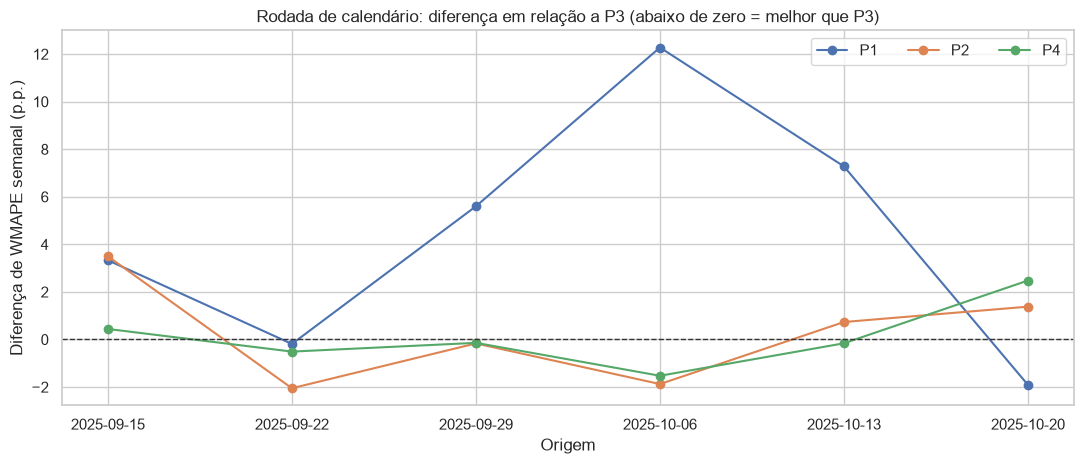

In [7]:
painel_calendario, pareada_calendario = exibir_rodada('calendário')
grafico_diferencas(
    ['P1', 'P2', 'P4'],
    'Rodada de calendário: diferença em relação a P3 (abaixo de zero = melhor que P3)',
    '021_diferenca_calendario.png',
)

**Resultado da rodada de calendário.** O calendário continua indispensável. Sem ele, `P0` tem WMAPE semanal de `44,35%` e diário de `70,82%`, e perde para `P3` em todas as origens. `P1`, que separa apenas o fim de semana, chega a `39,09%` no semanal e `50,96%` no diário, e perde no diário em todas as origens.

Entre os calendários mais detalhados, há empate no semanal: `P3` (`34,69%`), `P4` (`34,79%`) e `P2` (`34,94%`). A diferença aparece no diário: `P3` tem `37,83%`, contra `39,69%` de `P4` e `42,15%` de `P2`, e nenhum dos dois vence `P3` no diário em mais de uma origem. Separar a segunda-feira ou liberar os sete dias acrescenta parâmetros sem melhorar a previsão. `P3` permanece o calendário escolhido.

## 8. Rodada de forma funcional

Mantendo o calendário de `P3`, são comparadas as formas de potência, exponencial e linear. A forma
linear é inválida se produzir volume não positivo em qualquer previsão.

In [8]:
painel_forma, pareada_forma = exibir_rodada('forma')

,Parâmetros,WMAPE semanal (%),DP WMAPE semanal (p.p.),WMAPE diário (%),DP WMAPE diário (p.p.),RMSE (kg),DP RMSE (kg),MAE (kg),Erro absoluto mediano (kg),sMAPE (%),RMSLE,Viés (%),Pior erro semanal (%),Semanas dentro de ±5% (%),Semanas dentro de ±30% (%),Previsão mínima (kg),Elasticidade longo prazo (mediana)
Código,,,,,,,,,,,,,,,,,
E1,4,34.596,10.447,37.807,7.449,12.655,8.244,8.735,5.123,43.759,0.514,1.773,43.335,8.333,25.000,0.709,-8.376
P3,4,34.691,10.034,37.833,7.220,12.609,8.153,8.715,5.065,43.914,0.515,2.163,43.363,0.000,25.000,0.728,-8.279
L1,4,42.734,10.652,52.321,15.827,15.623,8.789,11.577,8.944,65.330,0.679,-12.443,51.761,0.000,16.667,-27.671,NaN


,Vitórias semanais,Dif. média WMAPE semanal (p.p.),Pior dif. semanal (p.p.),Melhor dif. semanal (p.p.),p-valor teste do sinal,Vitórias diárias,Dif. média WMAPE diário (p.p.),Válido,Sinal do lag estável,Promovido
Desafiante,,,,,,,,,,
E1,4 de 6,-0.094,0.411,-1.207,0.344,3 de 6,-0.026,True,True,False
L1,1 de 6,8.044,37.292,-2.344,0.984,0 de 6,14.487,False,True,False


**Resultado da rodada de forma.** Potência e exponencial são praticamente equivalentes: `E1` tem WMAPE semanal de `34,60%` contra `34,69%` de `P3`, vence em 4 de 6 origens com diferença média de `0,09` p.p. e empata no diário (3 de 6). A diferença é muito menor que a oscilação entre origens. Como ambas têm quatro parâmetros, `P3` é mantida porque sua inclinação é a própria elasticidade, constante ao longo do preço, e corresponde à forma `A/p^B` indicada no enunciado.

A forma linear `L1` é inválida: prevê volume mínimo de `-27,67 kg`, tem WMAPE diário de `52,32%` e viés de `-12,44%`.

## 9. Rodada de tendência

`T1` acrescenta `indice_tempo / 10` a `P3`. No horizonte de duas semanas, a tendência é extrapolada
além do último dia de ajuste. Esse é exatamente o uso que o otimizador faria, e por isso o
protocolo de origens é mais informativo sobre esse risco que a previsão de um passo do 2.0.

In [9]:
painel_tendencia, pareada_tendencia = exibir_rodada('tendência')

,Parâmetros,WMAPE semanal (%),DP WMAPE semanal (p.p.),WMAPE diário (%),DP WMAPE diário (p.p.),RMSE (kg),DP RMSE (kg),MAE (kg),Erro absoluto mediano (kg),sMAPE (%),RMSLE,Viés (%),Pior erro semanal (%),Semanas dentro de ±5% (%),Semanas dentro de ±30% (%),Previsão mínima (kg),Elasticidade longo prazo (mediana)
Código,,,,,,,,,,,,,,,,,
P3,4,34.691,10.034,37.833,7.220,12.609,8.153,8.715,5.065,43.914,0.515,2.163,43.363,0.0,25.0,0.728,-8.279
T1,5,50.604,24.253,52.620,22.614,15.205,8.551,10.977,8.198,54.178,0.610,15.791,66.391,0.0,25.0,0.779,-10.255


,Vitórias semanais,Dif. média WMAPE semanal (p.p.),Pior dif. semanal (p.p.),Melhor dif. semanal (p.p.),p-valor teste do sinal,Vitórias diárias,Dif. média WMAPE diário (p.p.),Válido,Sinal do lag estável,Promovido
Desafiante,,,,,,,,,,
T1,1 de 6,15.914,47.804,-2.915,0.984,1 de 6,14.787,True,True,False


**Resultado da rodada de tendência.** Este é o resultado que mais difere do 2.0. No protocolo de um passo, `T1` ficava próximo de `P3` (`35,94%` contra `35,29%` no diário). Quando precisa prever duas semanas adiante, a tendência é extrapolada e o erro dispara: WMAPE semanal de `50,60%`, DP de `24,25` p.p., viés de `+15,79%` e pior erro semanal médio de `66,39%`. `T1` perde para `P3` em 5 de 6 origens; na pior delas, erra `47,8` pontos a mais. O protocolo confirma, com evidência mais forte, a decisão do 2.0 de descartar a tendência.

## 10. Síntese sem memória e comparação com o 2.0

A tabela reúne os candidatos sem memória e compara a ordem obtida pelos dois protocolos. Se a
escolha for a mesma, ela não depende do método de validação. Os valores absolutos não são
comparáveis entre colunas: o 2.0 avalia somente 09/10 a 31/10 e reajusta o modelo a cada dia,
enquanto o 2.0.1 avalia seis origens com o modelo fixo durante duas semanas.

,2.0: WMAPE diário (%),2.0: WMAPE semanal (%),2.0.1: WMAPE diário (%),2.0.1: WMAPE semanal (%),2.0.1: DP semanal (p.p.),Posição 2.0 (diário),Posição 2.0.1 (semanal)
Código,,,,,,,
E1,35.44,30.65,37.81,34.60,10.45,2,1
P3,35.29,30.32,37.83,34.69,10.03,1,2
P4,38.16,32.04,39.69,34.79,8.91,4,3
P2,39.41,31.22,42.15,34.94,8.35,5,4
P1,53.51,30.38,50.96,39.09,13.12,6,5
L1,55.02,29.86,52.32,42.73,10.65,7,6
P0,78.00,30.26,70.82,44.35,16.30,8,7
T1,35.94,30.77,52.62,50.60,24.25,3,8


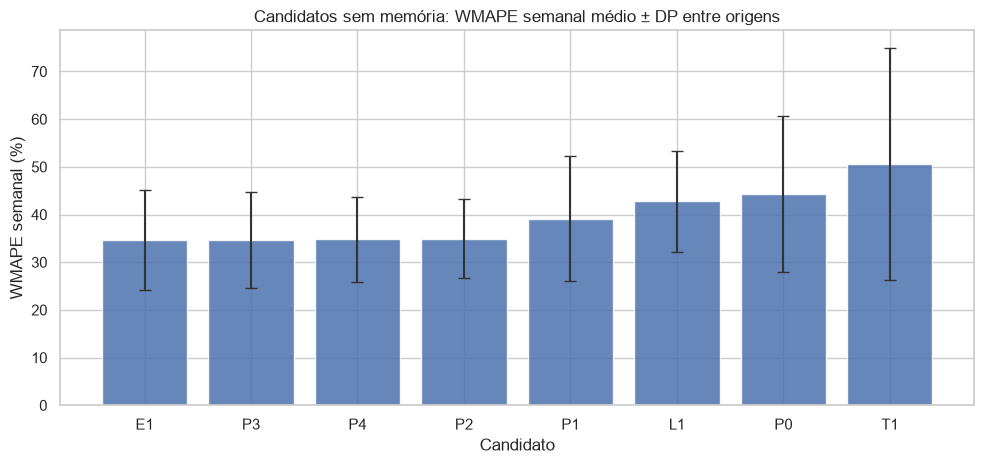

In [10]:
ranking_20 = pd.concat([
    pd.read_csv(path, index_col='Código')[['WMAPE', 'WMAPE semanal']]
    for path in RANKINGS_20.values()
])
ranking_20 = ranking_20.loc[~ranking_20.index.duplicated()]
painel_sem_memoria = montar_painel(list(CANDIDATOS_SEM_MEMORIA))
sintese = pd.DataFrame({
    '2.0: WMAPE diário (%)': 100 * ranking_20['WMAPE'],
    '2.0: WMAPE semanal (%)': 100 * ranking_20['WMAPE semanal'],
    '2.0.1: WMAPE diário (%)': painel_sem_memoria['WMAPE diário (%)'],
    '2.0.1: WMAPE semanal (%)': painel_sem_memoria['WMAPE semanal (%)'],
    '2.0.1: DP semanal (p.p.)': painel_sem_memoria['DP WMAPE semanal (p.p.)'],
}).loc[painel_sem_memoria.index]
sintese['Posição 2.0 (diário)'] = sintese['2.0: WMAPE diário (%)'].rank().astype(int)
sintese['Posição 2.0.1 (semanal)'] = sintese['2.0.1: WMAPE semanal (%)'].rank().astype(int)
sintese.to_csv(TABLES_DIR / '021_sintese_sem_memoria.csv')
display(sintese.round(2))

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(
    sintese.index, sintese['2.0.1: WMAPE semanal (%)'], color='#4c72b0', alpha=0.85,
)
ax.errorbar(
    sintese.index, sintese['2.0.1: WMAPE semanal (%)'],
    yerr=sintese['2.0.1: DP semanal (p.p.)'], fmt='none', ecolor='#333333', capsize=4,
)
ax.set(
    title='Candidatos sem memória: WMAPE semanal médio ± DP entre origens',
    xlabel='Candidato', ylabel='WMAPE semanal (%)',
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / '021_painel_sem_memoria.png', dpi=160, bbox_inches='tight')
plt.show()

**Resultado da síntese.** A ordem dos candidatos é praticamente a mesma nos dois protocolos. `P3` e `E1` ocupam as duas primeiras posições em ambos, seguidos por `P4` e `P2`; `P1`, `L1` e `P0` ficam no fim. A única mudança relevante é `T1`, que passa da terceira para a última posição quando a tendência precisa ser extrapolada por duas semanas.

Os erros do 2.0.1 são um pouco maiores que os do 2.0 porque o modelo não é atualizado durante as duas semanas e porque as origens começam com menos histórico e cobrem semanas diferentes. Esse é o erro mais realista para o uso no otimizador. A escolha de `P3` não depende do método de validação.

## 11. Desafio opcional de memória

Esta seção responde a uma pergunta diferente das anteriores: vale acrescentar memória de volume à
curva? Ela é tratada como desafio opcional porque a memória muda a natureza do otimizador. Sem
memória, o volume de cada dia depende apenas do preço daquele dia, e o problema pode ser resolvido
com uma tabela de preço × volume pré-calculada. Com lag, o volume de um dia depende de todos os
preços anteriores, a incerteza precisa ser simulada em trajetórias e o resultado passa a depender da
última venda observada. Essa complexidade só se justificaria com ganho consistente de previsão.

Nos modelos com lag, a elasticidade de `ln(preço)` é de **curto prazo**. O efeito total de uma
mudança permanente de preço é a elasticidade de **longo prazo**, `β / (1 − ρ)`, que é a apresentada no
painel e a única comparável à dos modelos sem lag.

,Parâmetros,WMAPE semanal (%),DP WMAPE semanal (p.p.),WMAPE diário (%),DP WMAPE diário (p.p.),RMSE (kg),DP RMSE (kg),MAE (kg),Erro absoluto mediano (kg),sMAPE (%),RMSLE,Viés (%),Pior erro semanal (%),Semanas dentro de ±5% (%),Semanas dentro de ±30% (%),Previsão mínima (kg),Elasticidade longo prazo (mediana)
Código,,,,,,,,,,,,,,,,,
P4-LU,6,32.234,8.150,37.212,7.070,12.200,7.556,8.329,5.050,43.086,0.496,4.395,39.606,8.333,25.000,0.732,-9.903
P4-LL,6,33.188,10.551,36.803,7.122,12.467,8.157,8.444,5.027,42.003,0.491,0.793,39.923,0.000,33.333,0.681,-9.890
P3,4,34.691,10.034,37.833,7.220,12.609,8.153,8.715,5.065,43.914,0.515,2.163,43.363,0.000,25.000,0.728,-8.279
P4,5,34.787,8.908,39.687,5.945,13.097,8.118,9.051,6.125,44.395,0.503,3.121,43.439,8.333,16.667,0.699,-8.883
P3-LU,5,35.000,9.873,37.725,7.542,12.582,8.210,8.696,5.276,43.942,0.517,2.512,43.813,0.000,25.000,0.735,-8.251
P3-LL,5,35.120,9.570,37.768,7.689,12.642,8.254,8.703,5.545,44.092,0.515,2.839,44.182,0.000,25.000,0.727,-8.163
P3-N,5,39.947,13.221,43.321,11.581,14.057,9.811,10.153,8.235,49.686,0.559,2.048,50.667,8.333,33.333,0.865,-8.279
P4-N,6,39.966,12.733,43.561,11.703,14.587,9.902,10.116,7.462,48.488,0.543,2.408,51.766,0.000,33.333,0.817,-8.883


,Vitórias semanais,Dif. média WMAPE semanal (p.p.),Pior dif. semanal (p.p.),Melhor dif. semanal (p.p.),p-valor teste do sinal,Vitórias diárias,Dif. média WMAPE diário (p.p.),Válido,Sinal do lag estável,Promovido
Desafiante,,,,,,,,,,
P4,4 de 6,0.097,2.479,-1.526,0.344,1 de 6,1.853,True,True,False
P3-LL,2 de 6,0.429,2.215,-0.949,0.891,2 de 6,-0.065,True,True,False
P4-LL,4 de 6,-1.502,2.668,-4.906,0.344,4 de 6,-1.030,True,True,False
P3-LU,0 de 6,0.310,0.771,0.001,1.000,2 de 6,-0.108,True,False,False
P4-LU,5 de 6,-2.457,6.376,-7.292,0.109,5 de 6,-0.621,True,True,False
P3-N,2 de 6,5.256,22.561,-6.986,0.891,2 de 6,5.487,True,True,False
P4-N,2 de 6,5.276,23.246,-6.331,0.891,2 de 6,5.727,True,True,False


Coeficiente do lag (ρ) por origem


candidato,P3-LL,P3-LU,P4-LL,P4-LU
origem,,,,
2025-09-15,-0.084,-0.038,0.157,0.291
2025-09-22,-0.090,-0.054,0.138,0.279
2025-09-29,-0.066,-0.017,0.165,0.296
2025-10-06,-0.067,-0.019,0.175,0.285
2025-10-13,-0.049,-0.004,0.154,0.255
2025-10-20,-0.028,0.023,0.171,0.286


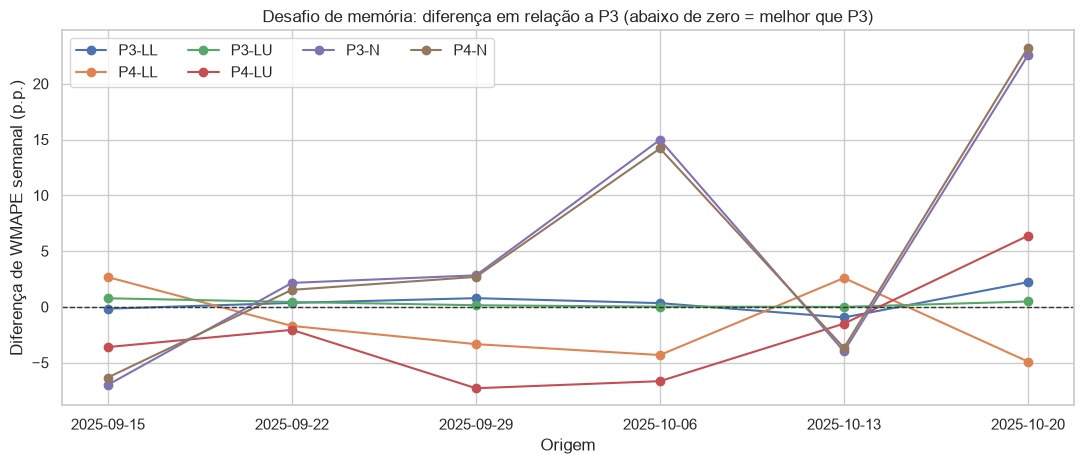

In [11]:
painel_memoria, pareada_memoria = exibir_rodada('memória')

rho_rodada = coeficientes_rodada.loc[
    coeficientes_rodada['candidato'].isin(['P3-LL', 'P4-LL', 'P3-LU', 'P4-LU'])
].pivot(index='origem', columns='candidato', values='Coeficiente do lag (ρ)')
print('Coeficiente do lag (ρ) por origem')
display(rho_rodada.round(3))

grafico_diferencas(
    list(CANDIDATOS_MEMORIA),
    'Desafio de memória: diferença em relação a P3 (abaixo de zero = melhor que P3)',
    '021_diferenca_memoria.png',
)

**Resultado do desafio de memória.** Nenhuma variante com memória cumpriu a regra de decisão.

- Com o calendário `P3`, o lag não ajuda: `P3-LL` e `P3-LU` ficam a menos de 0,5 ponto de `P3` e vencem em 2 e 0 de 6 origens. Em `P3-LU`, o coeficiente do lag ainda muda de sinal entre origens.
- `P4-LL`, que corresponde ao cenário 4 da tabela do colega, vence em 4 de 6 origens, com ganho médio de `1,50` p.p. e p-valor de `0,344`: compatível com acaso.
- `P4-LU` é o desafiante mais forte: vence em 5 de 6 origens, com ganho médio de `2,46` p.p. no semanal e `0,62` p.p. no diário, e coeficiente do lag positivo e estável (entre `0,26` e `0,30`). Mesmo assim, o p-valor do teste do sinal é `0,109`, e na origem 20/10 ele erra `6,38` pontos a mais que `P3`.
- O lag só fica estável quando a segunda-feira tem nível próprio, o que indica que ele está interagindo com o calendário (a sexta, de baixo volume, é o dia útil anterior da segunda) e não medindo uma dinâmica própria da demanda.
- Corrigir o nível pela última semana (`P3-N`, `P4-N`) piora a previsão em mais de 5 pontos e chega a errar `23` pontos a mais que `P3`.

O ganho possível do melhor lag, cerca de 2 pontos sem significância, não compensa transformar o otimizador em um problema dinâmico.

## 12. Decisão e estabilidade da elasticidade

A célula abaixo aplica a regra de decisão a todas as rodadas e registra a especificação mantida. Em
seguida, mostra como a elasticidade de longo prazo dos candidatos principais varia entre as origens,
à medida que o histórico de ajuste cresce. Para o otimizador, a elasticidade é o parâmetro que
transforma uma mudança de preço em mudança de volume.

Desafiantes promovidos: nenhum
Especificação mantida para o otimizador: P3
Elasticidade de longo prazo por origem


candidato,P1,P2,P3,P4,E1,T1
origem,,,,,,
2025-09-15,-3.614,-4.629,-6.625,-6.740,-6.602,-11.614
2025-09-22,-3.537,-5.059,-6.640,-6.596,-6.661,-11.651
2025-09-29,-6.467,-8.972,-9.128,-9.314,-9.184,-9.976
2025-10-06,-3.797,-8.867,-8.066,-8.717,-8.114,-6.736
2025-10-13,-5.607,-8.626,-8.492,-9.049,-8.637,-8.515
2025-10-20,-9.455,-11.032,-10.876,-11.356,-10.954,-10.534


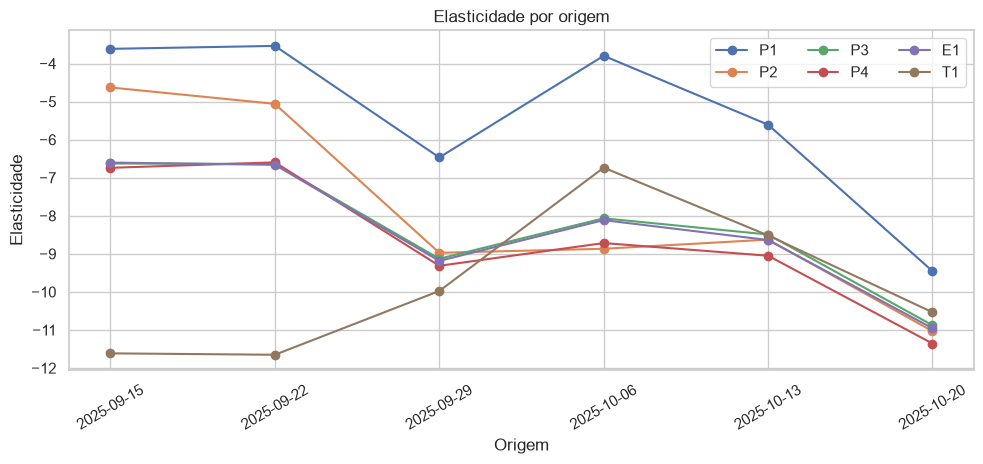

In [12]:
pareadas = pd.concat([
    pareada_calendario, pareada_forma, pareada_tendencia, pareada_memoria,
])
pareadas = pareadas.loc[~pareadas.index.duplicated()]
promovidos = pareadas.index[pareadas['Promovido']].tolist()
campeao_021 = promovidos[0] if len(promovidos) == 1 else REFERENCIA
print(f'Desafiantes promovidos: {promovidos or "nenhum"}')
print(f'Especificação mantida para o otimizador: {campeao_021}')

estabilidade = coeficientes_rodada.pivot(
    index='origem', columns='candidato', values='Elasticidade longo prazo'
)[['P1', 'P2', 'P3', 'P4', 'E1', 'T1']]
print('Elasticidade de longo prazo por origem')
display(estabilidade.round(3))

fig, ax = plt.subplots(figsize=(10, 4.8))
for code in estabilidade.columns:
    ax.plot(estabilidade.index.astype(str), estabilidade[code], marker='o', label=code)
ax.set(title='Elasticidade por origem', xlabel='Origem', ylabel='Elasticidade')
ax.tick_params(axis='x', rotation=30)
ax.legend(ncol=3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / '021_estabilidade_elasticidade.png', dpi=160, bbox_inches='tight')
plt.show()

**Resultado da decisão e da estabilidade.** Nenhum desafiante foi promovido, e `P3` permanece como especificação do otimizador.

A elasticidade de `P3` é negativa em todas as origens, mas sua magnitude cresce com o histórico: `-6,6` com ajuste até meados de setembro, `-9,1` no fim de setembro e `-10,9` com ajuste até 19/10, enquanto o ajuste completo do 2.0 resulta em `-12,36`. `P4`, `P2` e `E1` acompanham o mesmo padrão. Os modelos sem calendário adequado são instáveis: `P0` oscila entre `-2,3` e `-9,8`, e `P1` entre `-3,5` e `-9,5`, porque o preço passa a absorver diferenças de calendário.

Para o otimizador, isso significa que a sensibilidade à elasticidade deve ser testada com valores entre aproximadamente `-7` e `-16`, faixa coerente com o bootstrap do 2.0.

## 13. Erro semanal frente à tolerância da meta

A meta semanal admite uma faixa de tolerância. Se o erro de previsão do modelo for maior que essa
faixa, o otimizador pode recomendar preços que "cumprem a meta" na curva central, mas a erram na
realidade. A tabela lista cada semana validada pela especificação mantida, com erro em kg e em
percentual.

In [13]:
semanas_campeao = (
    previsoes_por_candidato[campeao_021]
    .groupby(['rodada', 'inicio_semana'])[['volume_real_kg', 'volume_previsto_kg']]
    .sum()
)
semanas_campeao['erro_kg'] = (
    semanas_campeao['volume_previsto_kg'] - semanas_campeao['volume_real_kg']
)
semanas_campeao['erro_%'] = 100 * semanas_campeao['erro_kg'] / semanas_campeao['volume_real_kg']
for tolerancia in TOLERANCIAS:
    semanas_campeao[f'dentro de ±{tolerancia:.0%}'] = (
        semanas_campeao['erro_%'].abs() <= 100 * tolerancia
    )
display(semanas_campeao.round(2))

semanas_distintas = semanas_campeao.index.get_level_values('inicio_semana').nunique()
print(
    f'Semanas distintas avaliadas: {semanas_distintas}; '
    f'mediana do erro absoluto semanal: {semanas_campeao["erro_%"].abs().median():.1f}%'
)

volume_real_kg  volume_previsto_kg  erro_kg  erro_%  \
rodada inicio_semana                                                        
1      2025-09-15              91.86              101.33     9.47   10.31   
       2025-09-22              70.02              102.03    32.02   45.73   
2      2025-09-22              70.02              100.65    30.64   43.76   
       2025-09-29              78.70              117.85    39.15   49.75   
3      2025-09-29              78.70              116.15    37.46   47.60   
       2025-10-06             234.29              159.25   -75.04  -32.03   
4      2025-10-06             234.29              146.17   -88.12  -37.61   
       2025-10-13             296.06              161.95  -134.11  -45.30   
5      2025-10-13             296.06              177.05  -119.00  -40.20   
       2025-10-20              79.29              101.17    21.88   27.59   
6      2025-10-20              79.29              104.36    25.06   31.61   
       2025-10-27              64.75               68.79     4.04    6.24   

                      dentro de ±5%  dentro de ±30%  
rodada inicio_semana                                 
1      2025-09-15             False            True  
       2025-09-22             False           False  
2      2025-09-22             False           False  
       2025-09-29             False           False  
3      2025-09-29             False           False  
       2025-10-06             False           False  
4      2025-10-06             False           False  
       2025-10-13             False           False  
5      2025-10-13             False           False  
       2025-10-20             False            True  
6      2025-10-20             False           False  
       2025-10-27             False            True

Semanas distintas avaliadas: 7; mediana do erro absoluto semanal: 38.9%


**Resultado frente à tolerância.** `P3` acerta o volume semanal dentro de ±30% em apenas 3 das 12 semanas validadas e em nenhuma semana dentro de ±5%. A mediana do erro semanal absoluto é `38,9%`. O padrão é claro: nas semanas de pico (06/10 e 13/10, com `234` e `296 kg`), o modelo subestima o volume entre `32%` e `45%`; nas semanas fracas de setembro, superestima entre `44%` e `50%`. A curva prevê bem o comportamento médio, mas não explica por que uma semana inteira vende o dobro de outra com preços semelhantes. Nenhum candidato testado resolve esse problema: o melhor resultado de semanas dentro de ±30% é `33%`.

Essa é a informação mais relevante para o otimizador: o erro típico da previsão semanal é maior que a própria tolerância da meta. Um plano que cumpre a meta na curva central tem chance elevada de não cumpri-la na realidade. Por isso, os cenários conservador e otimista e a análise de sensibilidade não são complementos opcionais; são parte necessária da recomendação.

## 14. Métricas incluídas e excluídas

O 2.0 já calculava um conjunto amplo de erros. Este notebook acrescenta somente métricas que mudam a
leitura para o otimizador e deixa de fora as que não medem previsão ou não se aplicam ao problema.

| Métrica | Situação | Motivo |
|---|---|---|
| WMAPE semanal | Promovida a primária | Mede o erro na mesma grandeza da meta |
| DP entre origens | Nova | Mostra a oscilação do erro entre períodos |
| Vitórias pareadas e teste do sinal | Nova | Compara modelos nos mesmos dias, descontando a dificuldade do período |
| Pior erro semanal | Nova | Representa o risco de uma semana muito mal prevista |
| Semanas dentro da tolerância | Nova | Traduz o erro na linguagem da restrição |
| Elasticidade por origem e de longo prazo | Nova | Mede a estabilidade do parâmetro usado pelo otimizador |
| WMAPE diário, MAE, RMSE, erro mediano, sMAPE, RMSLE, viés | Mantidas | Já eram adequadas |
| MAPE | Só diagnóstico | Dias com volume próximo de zero tornam a métrica instável |
| R² | Excluída da seleção | Mede ajuste dentro da amostra e em escala log, não erro de previsão |
| AIC e BIC | Excluídos da seleção | Também são medidas dentro da amostra; com lag, a primeira linha é descartada e as amostras deixam de ser iguais |
| Acurácia, AUC, matriz de confusão | Não se aplicam | São métricas de classificação, e volume em kg é uma quantidade contínua |
| Cobertura dos cenários conservador e otimista | Não calculada | Exigiria calibrar os multiplicadores dentro de cada origem com uma validação interna; com seis rodadas não há dados suficientes |

## 15. Conclusões

| Candidato | O que representa | WMAPE semanal | WMAPE diário | Complexidade no otimizador | Decisão |
|---|---|---:|---:|---|---|
| `P0` | Só preço | 44,35% | 70,82% | Mínima | Descartado: ignora o calendário |
| `P1` | Preço + fim de semana | 39,09% | 50,96% | Mínima | Descartado: perde no diário em todas as origens |
| `P2` | Preço + sete dias | 34,94% | 42,15% | Baixa, 8 parâmetros | Descartado: empata no semanal e piora no diário |
| **`P3`** | **Preço + seg–qui, sexta, fim de semana** | **34,69%** | **37,83%** | **Baixa, 4 parâmetros** | **Mantido** |
| `P4` | `P3` com segunda separada | 34,79% | 39,69% | Baixa, 5 parâmetros | Descartado: empata no semanal e piora no diário |
| `E1` | Forma exponencial | 34,60% | 37,81% | Baixa, 4 parâmetros | Equivalente a `P3`; `P3` preferido pela elasticidade constante e pela forma do enunciado |
| `L1` | Forma linear | 42,73% | 52,32% | Baixa | Inválido: prevê volume negativo |
| `T1` | `P3` + tendência | 50,60% | 52,62% | Baixa, mas extrapola o tempo | Descartado: a tendência degrada o horizonte de duas semanas |
| `P3-LL`, `P3-LU` | `P3` + lag | 35,1% e 35,0% | ~37,8% | Alta: otimizador dinâmico | Descartados: sem ganho |
| `P4-LL` | Cenário 4 do colega | 33,19% | 36,80% | Alta | Descartado: ganho compatível com acaso |
| `P4-LU` | `P4` + lag do dia útil | 32,23% | 37,21% | Alta | Não promovido: sinal promissor (5 de 6), sem evidência suficiente |
| `P3-N`, `P4-N` | Correção de nível recente | ~40,0% | ~43,4% | Média | Descartados: pioram a previsão |

1. O protocolo de origens semanais com horizonte de duas semanas mantém `P3` como especificação do otimizador. A ordem dos candidatos sem memória é praticamente a mesma do 2.0.
2. O calendário é indispensável; separar a segunda-feira ou detalhar os sete dias não melhora a previsão.
3. Potência e exponencial são equivalentes; a potência é preferida pela interpretação direta da elasticidade.
4. A tendência, que parecia quase neutra no 2.0, é claramente prejudicial quando extrapolada por duas semanas.
5. Nenhuma forma de memória compensa a complexidade que traria ao otimizador. `P4-LU` fica registrado como linha de investigação, a ser reavaliada se houver mais semanas de histórico.
6. O erro semanal típico (`~39%`) é maior que a tolerância da meta (`30%`). A incerteza deve entrar explicitamente na otimização, por cenários ou por análise de sensibilidade.
7. A elasticidade é negativa em todas as origens, mas sua magnitude cresce com o histórico. O otimizador deve ser testado em uma faixa de elasticidades, não apenas no valor central.
8. O conjunto de teste continua intocado. Ele deve ser consultado uma única vez, com o modelo congelado, para reportar o erro final.

Uma limitação permanece: as seis origens se sobrepõem e cobrem apenas sete semanas distintas. A validação é a mais fiel possível ao uso do modelo, mas tem pouco poder para distinguir candidatos com diferenças de 1 a 3 pontos.